# 01｜第 2 節：分類、正則化與非監督學習

**必做只有 3 組練習**：**讀取資料並切分 → 資料前處理 → Logistic Regression 訓練、預測與 Accuracy**。

先執行匯入套件 Cell。每組必做先看 Markdown 的程式範例，再在下方空白 Code Cell 照寫。**PCA、K-means、L1／L2 及其他延伸分析全部放在 Optional，程式已寫好，直接執行即可，不必照寫。**

請把 CSV 放在 Colab `/content` 或 Notebook 的工作目錄。本節與第 1 節**可以獨立執行**。


In [1]:
# Import the libraries used in this notebook.
# 匯入本份 Notebook 會用到的套件。
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, Ridge
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, accuracy_score, silhouette_score

# Use the requested Chinese font on systems where it is installed.
# 在已安裝微軟正黑體的系統使用此字型。
matplotlib.rc('font', family='Microsoft JhengHei')

# Draw minus signs using a widely supported character.
# 修正圖表座標軸的負號顯示。
matplotlib.rcParams['axes.unicode_minus'] = False

# Colab normally does not include Microsoft JhengHei; use English plot labels there.
# Colab 通常沒有微軟正黑體，這裡改用內建字型並使用英文圖表標籤。
if Path('/content').exists():
    matplotlib.rc('font', family='DejaVu Sans')

## 資料集欄位

| 欄位 | 內容 |
|---|---|
| `student_id` | 學生編號，不作為模型輸入 |
| `study_hours` | 每日讀書時數（含缺漏與一筆錯誤的 60 小時） |
| `practice_questions` | 每日練習題數（含缺漏） |
| `learning_method` | 自習、讀書會、線上課 |
| `attendance_rate` | 出席率，保留供延伸使用 |
| `sleep_hours` | 睡眠時數，保留供延伸使用 |
| `effort_level` | 學習投入程度，保留供延伸使用 |
| `quiz_score` | 小考分數：第 1 節迴歸預測目標 |
| `passed` | 是否及格（0：未及格，1：及格）：第 2 節分類目標 |

分類時的 **y 是 `passed`**；`quiz_score` **不能放入 X**，否則答案會提前洩漏。


## 必做：3 組練習


### 練習 1／3｜讀取資料、選擇 X／y、切分

現在要預測 `passed`（0／1）。已知 60 小時是錯誤資料，先標記為缺漏。**不能把 `quiz_score` 放入 X。**

**參考程式：**

```python
# Read the CSV and mark the impossible study hour as missing.
# 讀取資料，將不合理的讀書時數改成缺漏。
df = pd.read_csv('01_機器學習_學生練習資料_500筆.csv')
df.loc[df['study_hours'] > 24, 'study_hours'] = np.nan

# Select features and the classification target.
# 選擇輸入特徵與分類答案。
X = df[['study_hours', 'practice_questions', 'learning_method']]
y = df['passed']

# Split into training and testing sets.
# 切分訓練集與測試集。
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', len(X_train), 'Test:', len(X_test))
```

In [ ]:
# 請在此處根據範例練習程式碼



Train: 400 Test: 100


### 練習 2／3｜補值、獨熱編碼、標準化（同一個練習）

在同一個 Cell 中，依序完成 **① 補缺漏值 → ② One-Hot 獨熱編碼 → ③ StandardScaler 標準化**。

先用訓練集算出中位數，再分別補齊兩組資料的缺漏值；補值完成後才開始標準化。`fit_transform()` 只用在訓練集，測試集使用 `transform()`。這份資料的訓練集與測試集都有三種學習方式，因此練習中可以直接使用 `pd.get_dummies()`。

**參考程式：**

```python
# Select numerical features.
# 指定數值型特徵。
num_cols = ['study_hours', 'practice_questions']

# Calculate medians from training data.
# 使用訓練集計算中位數。
medians = X_train[num_cols].median()

# Fill missing values before scaling.
# 先補齊訓練集與測試集的缺漏值。
X_train_ready = X_train.fillna(medians)
X_test_ready = X_test.fillna(medians)

# Convert categories into 0/1 columns.
# 將類別資料轉成 0／1 欄位。
X_train_ready = pd.get_dummies(X_train_ready, dtype=int)
X_test_ready = pd.get_dummies(X_test_ready, dtype=int)

# Create a scaler.
# 建立標準化工具。
scaler = StandardScaler()

# Scale numerical columns using training data.
# 使用訓練集建立規則，再轉換數值欄位。
X_train_ready[num_cols] = scaler.fit_transform(X_train_ready[num_cols])
X_test_ready[num_cols] = scaler.transform(X_test_ready[num_cols])

# Preview the results.
# 檢視前五筆完成前處理的特徵。
display(X_train_ready.head())
```

In [ ]:
# 請在此處根據範例練習程式碼



,study_hours,practice_questions,learning_method_線上課,learning_method_自習,learning_method_讀書會
18,0.821282,1.537043,1,0,0
10,0.821282,1.293068,0,1,0
412,1.512887,0.561143,0,0,1
468,-0.242727,0.439155,0,0,1
284,0.182877,0.439155,0,1,0


### 練習 3／3｜訓練分類模型、預測與 Accuracy

預測及格（1）或未及格（0）。**Accuracy 是全部測試資料中預測正確的比例**。

**參考程式：**

```python
# Train the logistic regression classifier.
# 訓練邏輯斯迴歸分類模型。
model = LogisticRegression(max_iter=1000).fit(X_train_ready, y_train)

# Predict pass/fail labels for the test data.
# 預測測試集的及格或未及格標籤。
pred = model.predict(X_test_ready)

# Evaluate classification accuracy.
# 計算分類正確率。
print('Accuracy:', round(accuracy_score(y_test, pred), 2))

# Compare a few actual and predicted labels.
# 比較前五筆實際與預測標籤。
display(pd.DataFrame({
    'Actual': y_test.iloc[:5].values, 
    'Predicted': pred[:5]
}))
```

In [ ]:
# 請在此處根據範例練習程式碼



Accuracy: 0.9


,Actual,Predicted
0,1,1
1,1,1
2,1,1
3,0,0
4,0,0


## Optional｜進階觀察（可直接執行）

完成上方 **3 組必做**，就已走完一次「讀取資料 → 前處理 → 訓練 → 預測 → 評估」流程。

以下每個 Optional 都已提供完整程式，不需手動輸入。若有時間，再依興趣執行。

- **PCA**：將原本 5 個特徵降至指定維度，查看解釋變異及分類成效。
- **K-means**：指定分群數量 K、畫出分群結果；群數比較可另外執行。
- **L1／L2**：修改 `alpha`，觀察預測 MAE 與特徵權重。

**提醒：**PCA 的解釋變異不是 Accuracy；K-means 的分群標籤也不是「及格／未及格」。


### Optional A｜輸入三筆新資料，預測是否及格

沿用前面訓練好的 `scaler` 與 `model`，不重新 `fit()`。本範例的三筆新資料剛好包含三種學習方式，因此 One-Hot 後的欄位與訓練集相同，可直接預測。

**注意：**如果自行刪除某種學習方式，或換成其他資料，One-Hot 欄位可能不同；這份簡單範例只適用於目前固定的練習資料。

In [5]:
# Enter three new examples.
# 輸入三筆新的學習紀錄。
new_data = pd.DataFrame({
    'study_hours': [1.5, 3.0, 5.0],
    'practice_questions': [5, 12, 22],
    'learning_method': ['自習', '讀書會', '線上課']
})

# Fill missing values using training medians.
# 使用訓練集的中位數補齊缺漏值。
X_new_ready = new_data.fillna(medians)

# Convert categorical values into 0/1 columns.
# 將類別特徵轉成 0／1 欄位。
X_new_ready = pd.get_dummies(X_new_ready, dtype=int)

# Apply the original scaling rules.
# 使用原本的標準化規則轉換數值欄位。
X_new_ready[num_cols] = scaler.transform(X_new_ready[num_cols])


# Predict labels and probabilities.
# 預測及格標籤及其機率。
new_data['predicted_passed'] = model.predict(X_new_ready)
new_data['pass_probability'] = model.predict_proba(X_new_ready)[:, 1].round(2)

display(new_data)

,study_hours,practice_questions,learning_method,predicted_passed,pass_probability
0,1.5,5,自習,0,0.07
1,3.0,12,讀書會,1,0.60
2,5.0,22,線上課,1,0.98


### Optional B｜PCA：指定要降到幾個維度，再比較 Accuracy

**只需修改 `PCA_DIM`（例如 2 或 3）後執行此 Cell。** PCA 會從訓練資料學出新的主成分，再轉換測試資料。這裡同時比較降維前後的 Accuracy，讓學生觀察特徵變少後預測是否改變。


In [6]:
# Choose the number of principal components.
# 指定希望保留的主成分數量。
PCA_DIM = 2

# Fit PCA on the training features only.
# 僅使用訓練特徵建立 PCA。
pca = PCA(n_components=PCA_DIM)
X_train_pca = pca.fit_transform(X_train_ready)
X_test_pca = pca.transform(X_test_ready)

# Show the new dimensions and their explained variance.
# 顯示新維度數量與各主成分解釋變異比例。
print('Dimensions:', X_train_ready.shape[1], '→', X_train_pca.shape[1])
print('Explained variance:', pca.explained_variance_ratio_.round(3))

# Train a classifier on the PCA-reduced features.
# 用 PCA 後的特徵重新訓練分類模型。
pca_model = LogisticRegression(max_iter=1000).fit(X_train_pca, y_train)

# Compare accuracies without using the target during PCA fitting.
# 比較降維前後的分類正確率。
print('Original Accuracy:', round(accuracy_score(y_test, pred), 2))
print('PCA Accuracy:', round(accuracy_score(y_test, pca_model.predict(X_test_pca)), 2))

Dimensions: 5 → 2
Explained variance: [0.693 0.143]
Original Accuracy: 0.9
PCA Accuracy: 0.89


### Optional C｜PCA：比較各主成分的解釋變異

`PC1`、`PC2`……會依解釋變異比例由高到低排列。觀察 **Cumulative（累積解釋變異）**，可了解保留不同數量的主成分時，留下了多少原始資料的變異。**解釋變異較高，不保證分類 Accuracy 最高。**


,PC,Explained,Cumulative
0,1,0.693,0.693
1,2,0.143,0.836
2,3,0.098,0.934
3,4,0.066,1.000
4,5,0.000,1.000


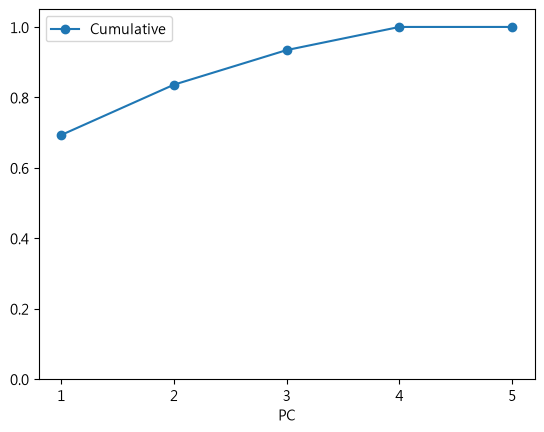

In [7]:
# Calculate explained variance for all components.
# 計算所有主成分的解釋變異比例。
all_pca = PCA().fit(X_train_ready)

# Show each component and cumulative explanation.
# 顯示每個主成分以及累積解釋變異。
variance = pd.DataFrame({
    'PC': range(1, len(all_pca.explained_variance_ratio_) + 1),
    'Explained': all_pca.explained_variance_ratio_}
)

variance['Cumulative'] = variance['Explained'].cumsum()
display(variance.round(3))

# Plot cumulative explained variance against dimensionality.
# 用圖形顯示不同維度保留的累積變異。
variance.plot(x='PC', y='Cumulative', marker='o', xticks=list(variance['PC']))

plt.ylim(0, 1.05)
plt.show()

### Optional D｜K-means：指定 K，直接看分群圖

**修改 `K`（例如 2、3、4）後執行此 Cell**，觀察散佈圖如何改變。分群只使用已標準化的兩個數值特徵，**不使用**及格標籤 `passed`；不同顏色代表不同群組，**黑色 X 表示各群的群中心**，不代表及格與否。


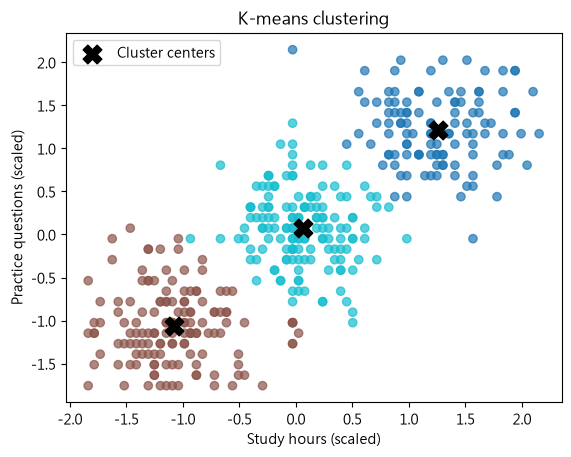

In [8]:
# Choose the number of clusters.
# 指定要分成幾群。
K = 3

# Select two features for clustering.
# 選擇兩個特徵進行分群。
X_train_cluster = X_train_ready[num_cols]

# Train K-means and assign cluster labels.
# 訓練 K-means 並取得每筆資料的群別。
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
groups = kmeans.fit_predict(X_train_cluster)

# Plot the clusters using two numerical features.
# 使用兩個數值欄位繪製分群散佈圖。
plt.scatter(X_train_cluster['study_hours'], X_train_cluster['practice_questions'], c=groups, cmap='tab10', alpha=0.7)

# Put the cluster centers in a small table with clear column names.
# 將分群中心整理成具有欄位名稱的表格。
centers = pd.DataFrame(kmeans.cluster_centers_, columns=num_cols)

# Mark each cluster center with a black X.
# 使用黑色 X 標示每一群的中心點。
plt.scatter(centers['study_hours'], centers['practice_questions'], marker='X', s=180, color='black', label='Cluster centers')
plt.xlabel('Study hours (scaled)')
plt.ylabel('Practice questions (scaled)')
plt.title('K-means clustering')
plt.legend()
plt.show()

### Optional E｜K-means：比較不同 K 的分群品質

直接執行即可比較 K＝2、3、4。**Inertia** 是群內距離平方和，K 增加通常會減少；**Silhouette** 越高通常代表群組越清楚。圖表橫軸顯示整數 K。


,Inertia,Silhouette
2,282.065,0.504
3,127.295,0.550
4,107.009,0.459


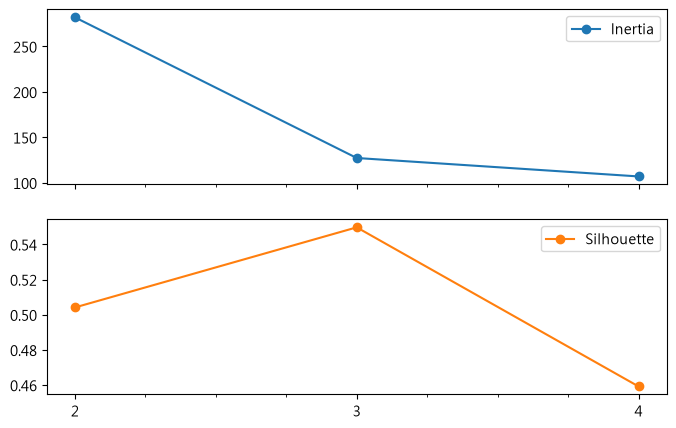

In [9]:
# Select the two numerical features for clustering.
# 選取兩個數值欄位作為分群輸入。
X_train_cluster = X_train_ready[num_cols]

# Save K-means evaluation scores in a table.
# 建立記錄分群結果的表格。
results = pd.DataFrame(columns=['Inertia', 'Silhouette'])

# Try two, three, and four groups.
# 比較分成兩群、三群與四群。
for k in [2, 3, 4]:
    trial = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_train_cluster)
    results.loc[k] = [trial.inertia_, silhouette_score(X_train_cluster, trial.labels_)]

# Show both metrics with integer ticks.
# 顯示評估指標，並使用整數刻度。
display(results.round(3))

results.plot(subplots=True, marker='o', figsize=(8, 5), xticks=[2, 3, 4])

plt.show()

### Optional F｜L1／L2 正則化：改 alpha，比較 MAE 與權重

這裡改以 `quiz_score`（小考分數）做迴歸，對照沒有正則化的 `LinearRegression`、L1 的 `Lasso` 及 L2 的 `Ridge`。可以修改 `L1_ALPHA`、`L2_ALPHA`，觀察 MAE 和權重圖。`alpha=1` 是示範起點，**不代表最佳值**；正式調參應使用驗證資料。


No penalty MAE: 5.87
L1 MAE: 6.25
L2 MAE: 5.87


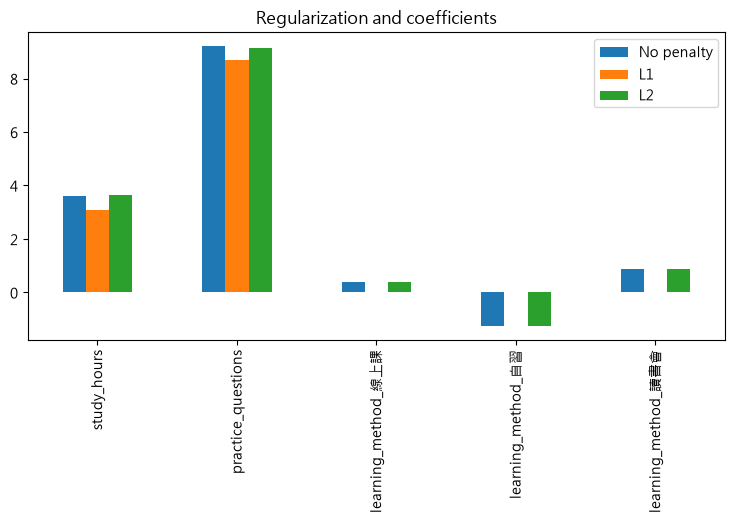

In [10]:
# Choose regularization strengths.
# 設定 L1 與 L2 正則化強度。
L1_ALPHA = 1
L2_ALPHA = 1

# Use quiz scores for the regression task.
# 以小考分數作為迴歸預測目標。
score_train = df.loc[X_train.index, 'quiz_score']
score_test = df.loc[X_test.index, 'quiz_score']

# Fit the three regression models.
# 訓練無正則化、L1、L2 三個迴歸模型。
plain = LinearRegression().fit(X_train_ready, score_train)
l1 = Lasso(alpha=L1_ALPHA).fit(X_train_ready, score_train)
l2 = Ridge(alpha=L2_ALPHA).fit(X_train_ready, score_train)

# Compare prediction errors (MAE).
# 使用預測結果比較三個模型的 MAE。
print('No penalty MAE:', round(mean_absolute_error(score_test, plain.predict(X_test_ready)), 2))
print('L1 MAE:', round(mean_absolute_error(score_test, l1.predict(X_test_ready)), 2))
print('L2 MAE:', round(mean_absolute_error(score_test, l2.predict(X_test_ready)), 2))

# Compare the learned coefficients.
# 比較三種模型學到的特徵權重。
pd.DataFrame({'No penalty': plain.coef_, 'L1': l1.coef_, 'L2': l2.coef_}, index=X_train_ready.columns).plot(kind='bar', figsize=(9, 4))
plt.title('Regularization and coefficients')
plt.show()

**第 2 節完成。** 只要完成 **3 組必做練習**，就已能獨立完成資料前處理、分類模型訓練、預測與 Accuracy 評估。PCA、K-means 和其他延伸內容全部為 Optional，可依課堂時間選擇執行。
